# 01 · Data audit (Phase 0–1)
**Question:** which datasets exist for SIH26066, do they cover 2021, and how does each one's grid line up with ours?

Everything below is read from the JSON the audit/download code wrote (`data/audit/`), nothing is typed by hand.
Code: `src/oceanembed_ml/audit/`, `src/oceanembed_ml/data/download_*.py`.

In [1]:
import json, warnings
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
from oceanembed_ml.config import ROOT, AUDIT, INTERIM, PROCESSED, FINAL, FIGURES, load_yaml
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)
print("project root:", ROOT)

project root: D:\Ml project


## Canonical grid (single source of truth: `configs/grid.yaml`)

In [2]:
grid = load_yaml("grid.yaml"); d = grid["domain"]
print(f"lat {d['lat_min']}–{d['lat_max']}, lon {d['lon_min']}–{d['lon_max']}, res {d['res']}°")
print("depths (m):", grid["depths"])

lat 5.0–30.0, lon 45.0–105.0, res 0.25°
depths (m): [0, 5, 10, 20, 30, 50, 75, 100, 125, 150, 200, 300, 500, 700, 1000]


## Copernicus catalogue: variables, units, coverage

In [3]:
cat = json.loads((AUDIT/"cmems_catalogue.json").read_text())
rows = []
for pid, p in cat["products"].items():
    for ds in p.get("datasets", []):
        for v, info in ds["variables"].items():
            c = info["coords"]; t = c.get("time", {})
            rows.append(dict(product=pid, dataset=ds["dataset_id"], variable=v, units=info["units"],
                             step_deg=c.get("latitude", {}).get("step"), start=(t.get("min_iso") or "")[:10], end=(t.get("max_iso") or "")[:10]))
df = pd.DataFrame(rows)
used = ["thetao_glor","thetao","analysed_sst","sos","sla","ugos","vgos","eastward_wind","northward_wind"]
df[df.variable.isin(used) & ~df.dataset.str.contains("P1M|mnstd|nrt|demo|0.25deg_PT1H")].reset_index(drop=True)

,product,dataset,variable,units,step_deg,start,end
0,GLOBAL_MULTIYEAR_PHY_ENS_001_031,cmems_mod_glo_phy-all_my_0.25deg_P1D-m,thetao_glor,degrees_C,0.250000,1993-01-01,2025-12-31
1,GLOBAL_MULTIYEAR_PHY_001_030,cmems_mod_glo_phy_my_0.083deg_P1D-m,thetao,degrees_C,0.083333,1993-01-01,2026-09-22
2,SST_GLO_SST_L4_REP_OBSERVATIONS_010_011,METOFFICE-GLO-SST-L4-REP-OBS-SST,analysed_sst,kelvin,0.050000,1981-10-01,2026-06-30
3,SST_GLO_SST_L4_NRT_OBSERVATIONS_010_001,METOFFICE-GLO-SST-L4-NRT-OBS-SST-V2,analysed_sst,kelvin,0.050000,2024-01-17,2026-11-15
4,MULTIOBS_GLO_PHY_S_SURFACE_MYNRT_015_013,cmems_obs-mob_glo_phy-sss_my_multi_P1D,sos,.001,0.125000,1993-01-01,2024-12-15
5,SEALEVEL_GLO_PHY_L4_MY_008_047,cmems_obs-sl_glo_phy-ssh_my_allsat-l4-duacs-0....,sla,m,0.125000,1993-01-01,2026-05-15
6,SEALEVEL_GLO_PHY_L4_MY_008_047,cmems_obs-sl_glo_phy-ssh_my_allsat-l4-duacs-0....,ugos,m/s,0.125000,1993-01-01,2026-05-15
7,SEALEVEL_GLO_PHY_L4_MY_008_047,cmems_obs-sl_glo_phy-ssh_my_allsat-l4-duacs-0....,vgos,m/s,0.125000,1993-01-01,2026-05-15
8,WIND_GLO_PHY_L4_MY_012_006,cmems_obs-wind_glo_phy_my_l4_0.125deg_PT1H,eastward_wind,m s-1,0.125000,2007-01-11,2026-07-21
9,WIND_GLO_PHY_L4_MY_012_006,cmems_obs-wind_glo_phy_my_l4_0.125deg_PT1H,northward_wind,m s-1,0.125000,2007-01-11,2026-07-21


## Grid alignment → which regridding operator each source needs

In [4]:
ga = json.loads((AUDIT/"grid_alignment.json").read_text())
pd.DataFrame([{**{"source": k}, "native_step": v["native_step_deg"], "centre_offset": v["centre_offset_deg"],
               "operator": v["operator"], "GB (2021)": v["volume_estimate"]["uncompressed_GB_float32"]} for k, v in ga["sources"].items()])

,source,native_step,centre_offset,operator,GB (2021)
0,glorys_ens (target),0.250000,"[0.0, 0.0]",exact_select,1.77
1,glorys12 (target alt.),0.083333,"[0.0, 0.0]",block_mean_3x3,12.06
2,glorys12_clim (baseline),0.083333,"[0.0, 0.0]",block_mean_3x3,0.40
3,ostia_rep (sst),0.050000,"[0.025002, 0.024994]",conservative_area_weighted,0.93
4,sss_multiobs (sss),0.125000,"[0.0625, 0.0625]",block_mean_2x2,0.15
5,"duacs (sla, ugos, vgos)",0.125000,"[0.0625, 0.0625]",block_mean_2x2,0.45
6,"cmems_winds 0.125 (u10, v10)",0.125000,"[0.0625, 0.0625]",block_mean_2x2,7.16


## ARGO (independent validation) and download verification

{'n_profiles': 4071, 'n_floats': 99, 'n_delayed_mode': 3724, 'n_profiles_arabian_sea': 2858, 'n_profiles_bay_of_bengal': 1024}


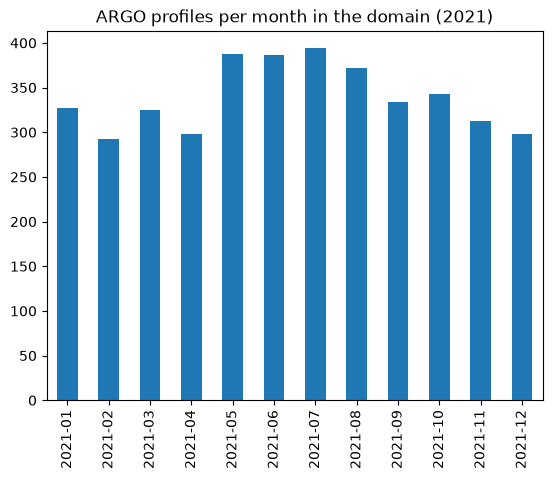

,n_files,expected_files,total_MB,complete
glorys,12,12,1765.5,True
glorys_clim,1,1,198.2,True
sst,12,12,463.6,True
sss,12,12,148.5,True
ssh,12,12,445.0,True
winds,12,12,3557.1,True
argo,4071,4071,242.9,True
ibtracs,1,1,27.9,True


In [5]:
argo = json.loads((AUDIT/"argo_index_summary.json").read_text())
print({k: argo[k] for k in ["n_profiles","n_floats","n_delayed_mode","n_profiles_arabian_sea","n_profiles_bay_of_bengal"]})
pd.Series(argo["profiles_per_month"]).plot.bar(title="ARGO profiles per month in the domain (2021)"); plt.show()
rv = json.loads((AUDIT/"raw_verification.json").read_text())
pd.DataFrame(rv["sources"]).T[["n_files","expected_files","total_MB","complete"]]